In [1]:
import specpolFlow as pol
import matplotlib.pyplot as plt
import VPtools as vp
import numpy as np
from pathlib import Path
import math
from matplotlib.gridspec import GridSpec
path_google = 'G:/Shared drives/'
obs_folder = Path(r"G:\Shared drives\BinamicsOstars\DataFromEve\spectra_tovero")
# import normPlot
import pandas as pd


In [2]:
hd = "hd191201"    

obs = sorted([f.name for f in obs_folder.glob(f"{hd}*.s")])

print(f"Found {len(obs)} observations for {hd}:")
for f in obs:
    print(f)
print(obs)

filename1 = obs[0]
filename2 = obs[1]

spec1 = pol.read_spectrum(obs_folder / filename1)
spec1 = spec1.merge_orders(mode="trim")
# spec2 = pol.read_spectrum(obs_folder / filename2)
# spec2 = spec2.merge_orders(mode="trim")

label1 = filename1.replace("_rn.s", "")
# label2 = filename2.replace("_rn.s", "")
spec = spec1
name = filename1

Found 2 observations for hd191201:
hd191201_E_1308737pn_rn.s
hd191201_E_1720107pnm_rn.s
['hd191201_E_1308737pn_rn.s', 'hd191201_E_1720107pnm_rn.s']


Make LSD line profiles

In [ ]:
# VALD_file_name = 'LongList_T30000G375.dat'
# file_output = 'T30000_depth0.01.mask'
# mask = pol.make_mask(VALD_file_name, outMaskName = file_output, 
#                      depthCutoff = 0.01, atomsOnly = True)

# velrange = 600.0

# excluded_regions = (
#     pol.get_Balmer_regions_default(velrange)
#     + pol.get_telluric_regions_default()
# )


# mask_clean = mask.clean(excluded_regions)
# mask_clean.save(r"T30000G375_depth0.01_clean.mask")



missing Lande factors for 185 lines (skipped) from:
[np.str_('He 2'), np.str_('O 2')]
skipped all lines for species:
[np.str_('H 1')]


In [3]:
# Line mask tweaking
mask_clean='T30000G375_depth0.01_clean.mask' #path of the cleaned mask
# mask_tweaked='T30000G375_depth0.01_cleantweaked.mask' #path of the new tweaked mask
sfile = obs_folder/filename1
# print(sfile)


Modified line mask, removed 153 too closely spaced lines
Average observed spec velocity spacing: 1.806632 km/s
using a 116 point profile with 7.000000 km/s pixels
mean mask depth 0.081543 wl 498.864 Lande 1.171177 (from 1024 lines)
mean mask norm weightI 0.407715 weightV 0.382674
saving model spectrum to  ...
I reduced chi2 259.9248 (chi2 32137366.10 constraints 123757 dof 116)
 Rescaling error bars by: 16.122184
V reduced chi2 1.2082 (chi2 149382.55 constraints 123757 dof 116)
 Rescaling error bars by: 1.099180
 removing profile continuum pol: -5.1144e-06 +/- 2.3616e-09 (avg err 4.8522e-05)
N1 reduced chi2 1.2141 (chi2 150118.28 constraints 123757 dof 116)
 Rescaling error bars by: 1.101883
 removing profile continuum pol: -4.5437e-06 +/- 2.3733e-09 (avg err 4.8642e-05)
(possible Stokes I uncertainty underestimate 1.9816e-03 vs 7.2554e-04)
line range estimate -232.0 230.0 km/s
V in line reduced chi^2 0.889835 (chi2  16.017031) 
 detect prob 0.408641 (fap 5.913587e-01)
 Non-detection V

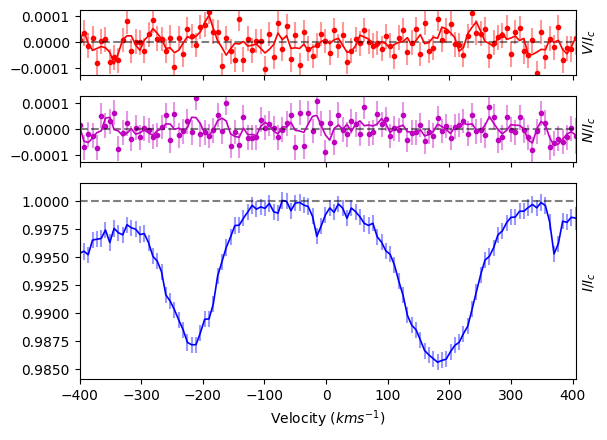

In [12]:
# Calculate LSD 
# clean_Mask_filename = 'T30000G375_depth0.01_cleantweaked.mask'
LSD_outfile = 'lsdoutputsHD191201/hd191201_E_1308737pn_vp7.lsd'
lsd, mod = pol.run_lsdpy(obs = sfile, mask = mask_clean, outLSDName = LSD_outfile, 
           velStart = -400, velEnd = 400.0, velPixel =7,  # number of points / vsini
           normDepth = 0.2, normLande = 1.2, normWave = 500.0)
# figure out what are the lines in Stoke V and Null profiles

Modified line mask, removed 70 too closely spaced lines
Average observed spec velocity spacing: 1.806632 km/s
using a 443 point profile with 1.810000 km/s pixels
mean mask depth 0.075487 wl 497.073 Lande 1.166212 (from 1107 lines)
mean mask norm weightI 0.377435 weightV 0.355345
saving model spectrum to  ...
I reduced chi2 251.8436 (chi2 30957873.43 constraints 123368 dof 443)
 Rescaling error bars by: 15.869581
V reduced chi2 1.2079 (chi2 148483.66 constraints 123368 dof 443)
 Rescaling error bars by: 1.099054
 removing profile continuum pol: -5.2308e-06 +/- 9.3925e-09 (avg err 9.6863e-05)
N1 reduced chi2 1.2140 (chi2 149230.37 constraints 123368 dof 443)
 Rescaling error bars by: 1.101815
 removing profile continuum pol: -4.1805e-06 +/- 9.4398e-09 (avg err 9.7106e-05)
line range estimate -247.9599999999998 237.1200000000008 km/s
V in line reduced chi^2 1.307053 (chi2 125.477086) 
 detect prob 0.976640 (fap 2.335958e-02)
 Non-detection V (fap 2.335958e-02)
 V outside line reduced chi^

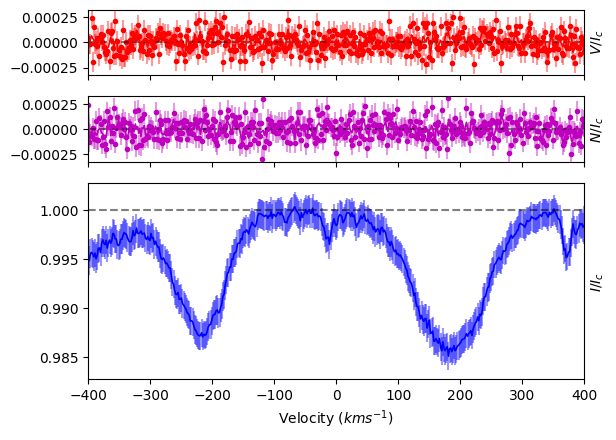

Modified line mask, removed 51 too closely spaced lines
Average observed spec velocity spacing: 1.806632 km/s
using a 801 point profile with 1.000000 km/s pixels
mean mask depth 0.074559 wl 496.785 Lande 1.166957 (from 1126 lines)
mean mask norm weightI 0.372793 weightV 0.352026
saving model spectrum to  ...
I reduced chi2 249.0476 (chi2 30513814.64 constraints 123323 dof 801)
 Rescaling error bars by: 15.781243
V reduced chi2 1.2080 (chi2 148000.53 constraints 123323 dof 801)
 Rescaling error bars by: 1.099068
 removing profile continuum pol: -5.3425e-06 +/- 1.8198e-08 (avg err 1.3478e-04)
N1 reduced chi2 1.2139 (chi2 148726.25 constraints 123323 dof 801)
 Rescaling error bars by: 1.101759
 removing profile continuum pol: -3.9943e-06 +/- 1.8287e-08 (avg err 1.3511e-04)
line range estimate -256 239 km/s
V in line reduced chi^2 1.263227 (chi2 146.534283) 
 detect prob 0.970925 (fap 2.907530e-02)
 Non-detection V (fap 2.907530e-02)
 V outside line reduced chi^2 1.007348 (chi2 683.989325)

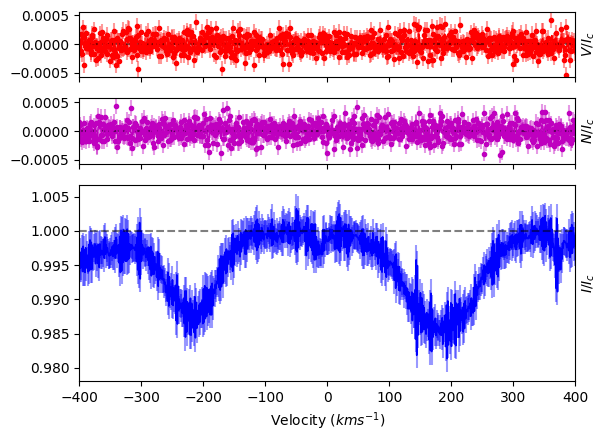

Modified line mask, removed 108 too closely spaced lines
Average observed spec velocity spacing: 1.806632 km/s
using a 201 point profile with 4.000000 km/s pixels
mean mask depth 0.078170 wl 497.570 Lande 1.166806 (from 1069 lines)
mean mask norm weightI 0.390851 weightV 0.367043
saving model spectrum to  ...
I reduced chi2 253.8142 (chi2 31287934.82 constraints 123472 dof 201)
 Rescaling error bars by: 15.931548
V reduced chi2 1.2082 (chi2 148934.28 constraints 123472 dof 201)
 Rescaling error bars by: 1.099175
 removing profile continuum pol: -5.4583e-06 +/- 4.2685e-09 (avg err 6.5282e-05)
N1 reduced chi2 1.2144 (chi2 149695.65 constraints 123472 dof 201)
 Rescaling error bars by: 1.101981
 removing profile continuum pol: -4.1468e-06 +/- 4.2903e-09 (avg err 6.5449e-05)
(possible Stokes I uncertainty underestimate 1.4077e-03 vs 9.8179e-04)
line range estimate -260 244 km/s
V in line reduced chi^2 1.510414 (chi2  77.031129) 
 detect prob 0.989265 (fap 1.073536e-02)
 Non-detection V (fa

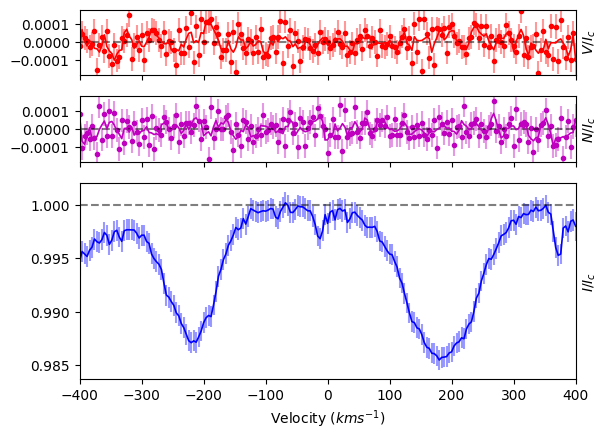

Modified line mask, removed 153 too closely spaced lines
Average observed spec velocity spacing: 1.806632 km/s
using a 116 point profile with 7.000000 km/s pixels
mean mask depth 0.081543 wl 498.864 Lande 1.171177 (from 1024 lines)
mean mask norm weightI 0.407715 weightV 0.382674
saving model spectrum to  ...
I reduced chi2 259.9248 (chi2 32137366.10 constraints 123757 dof 116)
 Rescaling error bars by: 16.122184
V reduced chi2 1.2082 (chi2 149382.55 constraints 123757 dof 116)
 Rescaling error bars by: 1.099180
 removing profile continuum pol: -5.1144e-06 +/- 2.3616e-09 (avg err 4.8522e-05)
N1 reduced chi2 1.2141 (chi2 150118.28 constraints 123757 dof 116)
 Rescaling error bars by: 1.101883
 removing profile continuum pol: -4.5437e-06 +/- 2.3733e-09 (avg err 4.8642e-05)
(possible Stokes I uncertainty underestimate 1.9816e-03 vs 7.2554e-04)
line range estimate -232 230 km/s
V in line reduced chi^2 0.889835 (chi2  16.017031) 
 detect prob 0.408641 (fap 5.913587e-01)
 Non-detection V (fa

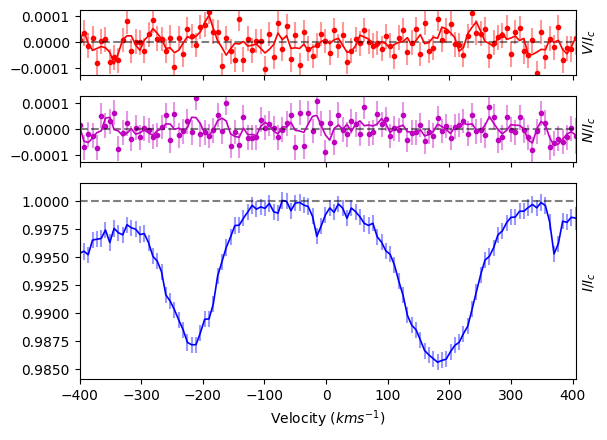

Modified line mask, removed 195 too closely spaced lines
Average observed spec velocity spacing: 1.806632 km/s
using a 81 point profile with 10.000000 km/s pixels
mean mask depth 0.084868 wl 499.608 Lande 1.171233 (from 982 lines)
mean mask norm weightI 0.424338 weightV 0.398693
saving model spectrum to  ...
I reduced chi2 261.4015 (chi2 32333539.65 constraints 123774 dof 81)
 Rescaling error bars by: 16.167917
V reduced chi2 1.2082 (chi2 149441.15 constraints 123774 dof 81)
 Rescaling error bars by: 1.099164
 removing profile continuum pol: -5.2573e-06 +/- 1.6726e-09 (avg err 4.0823e-05)
N1 reduced chi2 1.2142 (chi2 150190.40 constraints 123774 dof 81)
 Rescaling error bars by: 1.101916
 removing profile continuum pol: -4.3967e-06 +/- 1.6810e-09 (avg err 4.0925e-05)
(possible Stokes I uncertainty underestimate 4.4082e-03 vs 6.1436e-04)
ERROR: could not find line range!  (using full profile)
V in line reduced chi^2 1.147392 (chi2  87.201757) 
 detect prob 0.821449 (fap 1.785510e-01)
 N

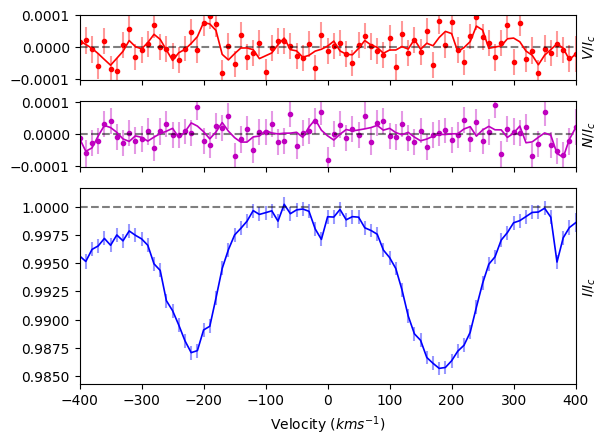

Modified line mask, removed 259 too closely spaced lines
Average observed spec velocity spacing: 1.806632 km/s
using a 55 point profile with 15.000000 km/s pixels
mean mask depth 0.089718 wl 501.693 Lande 1.172493 (from 918 lines)
mean mask norm weightI 0.448589 weightV 0.424624
saving model spectrum to  ...
I reduced chi2 274.2244 (chi2 34065255.50 constraints 124279 dof 55)
 Rescaling error bars by: 16.559723
V reduced chi2 1.2080 (chi2 150065.16 constraints 124279 dof 55)
 Rescaling error bars by: 1.099100
 removing profile continuum pol: -4.8512e-06 +/- 1.0877e-09 (avg err 3.2892e-05)
N1 reduced chi2 1.2137 (chi2 150776.63 constraints 124279 dof 55)
 Rescaling error bars by: 1.101702
 removing profile continuum pol: -5.3027e-06 +/- 1.0929e-09 (avg err 3.2970e-05)
(possible Stokes I uncertainty underestimate 4.4922e-03 vs 4.9912e-04)
ERROR: could not find line range!  (using full profile)
V in line reduced chi^2 1.353086 (chi2  67.654282) 
 detect prob 0.951250 (fap 4.874981e-02)
 N

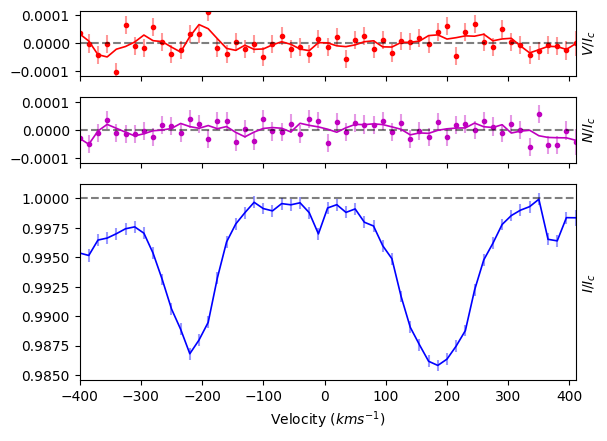

In [ ]:
velPixels = [None, 1, 4, 7, 10, 15]
# velPixels = [None]
lsd_folder = Path('lsdoutputsHD191201/lsdprofiles_changingVelPixel')
lsd_folder.mkdir(exist_ok=True)
Bz_results = {}

for velPixel in velPixels:
    label = 'default' if velPixel is None else f'vp{velPixel}'
    LSD_outfile = lsd_folder / f'hd191201_E_1308737pn_{label}.lsd'
    kwargs = {} if velPixel is None else {'velPixel': velPixel}

    lsd, mod = pol.run_lsdpy(obs=sfile, mask=mask_clean, outLSDName=str(LSD_outfile),
                            velStart=-400, velEnd=400, normDepth=0.2, normLande=1.2, normWave=500.0,
                            plotLSD=True, outPlotLSDName=str(lsd_folder / f'hd191201_E_1308737pn_{label}_LSD.pdf'),
                            **kwargs)
    lsd.save(LSD_outfile)
    # Bz, fig = lsd.calc_bz(cog='I', norm=1.0, velrange=[-300,-100], bzwidth=80,
    #                     lambda0=500.0, geff=1.2, plot=True, figsize=(6,6))

    # result = (f"Bz = {Bz['V bz (G)']:.1f} ± {Bz['V bz sig (G)']:.1f} G\n"
    #         f"V FAP = {Bz['V FAP']:.3g}\n"
    #         f"Null Bz = {Bz['N1 bz (G)']:.1f} ± {Bz['N1 bz sig (G)']:.1f} G\n"
    #         f"Null FAP = {Bz['N1 FAP']:.3g}")
    # Bz_results[label] = Bz
    # fig.subplots_adjust(bottom=0.23)
    # fig.text(0.15, 0.02, result, fontsize=9, va='bottom')
    # fig.savefig(output_folder / f'hd191201_E_1308737pn_LeftComponent_{label}_norm1.0_Bz.pdf', bbox_inches='tight')
    # print(f'{label}: Bz = {Bz}')

default: Bz = {'V bz (G)': np.float64(-23.120463377410378), 'V bz sig (G)': np.float64(107.17322054716409), 'V FAP': np.float64(0.38927624972577557), 'N1 bz (G)': np.float64(-106.09563841674797), 'N1 bz sig (G)': np.float64(107.48646565749635), 'N1 FAP': np.float64(0.8722695381805022), 'N2 bz (G)': 0.0, 'N2 bz sig (G)': 0.0, 'N2 FAP': 0.0, 'norm_method': 'auto', 'norm': np.float64(0.9973879), 'cog_method': 'I', 'cog': np.float64(-230.74003101284353), 'int. range start': np.float64(-310.74003101284353), 'int. range end': np.float64(-150.74003101284353)}
vp1: Bz = {'V bz (G)': np.float64(-31.540558427104337), 'V bz sig (G)': np.float64(114.56829839815514), 'V FAP': np.float64(0.20133760981309756), 'N1 bz (G)': np.float64(-85.74127536634784), 'N1 bz sig (G)': np.float64(114.87615358275296), 'N1 FAP': np.float64(0.3427005197562293), 'N2 bz (G)': 0.0, 'N2 bz sig (G)': 0.0, 'N2 FAP': 0.0, 'norm_method': 'auto', 'norm': np.float64(0.9973180500000001), 'cog_method': 'I', 'cog': np.float64(-231

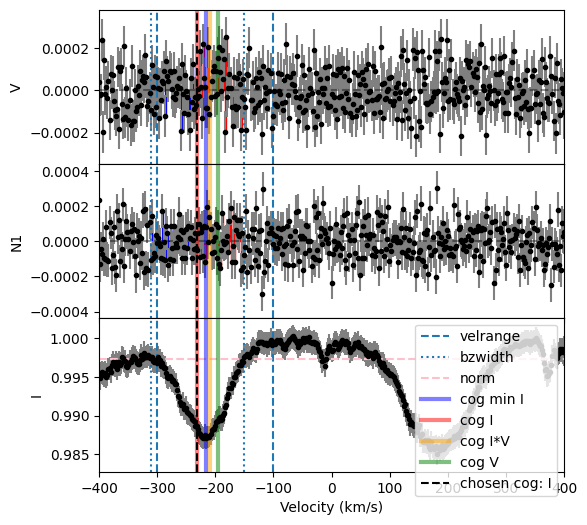

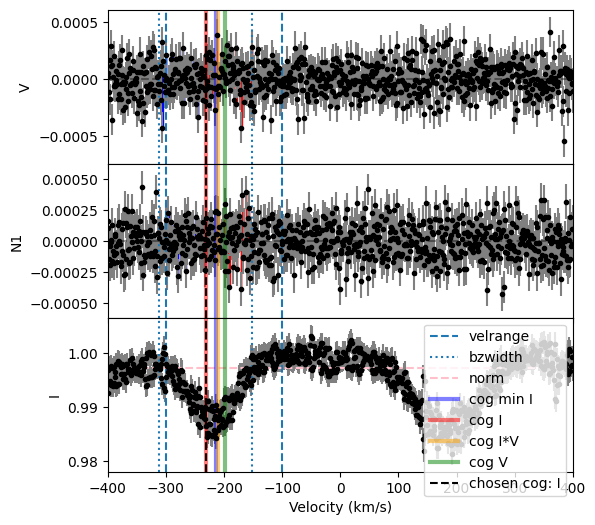

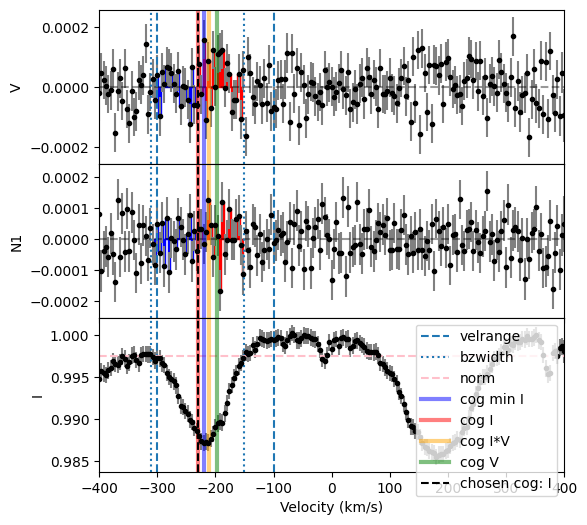

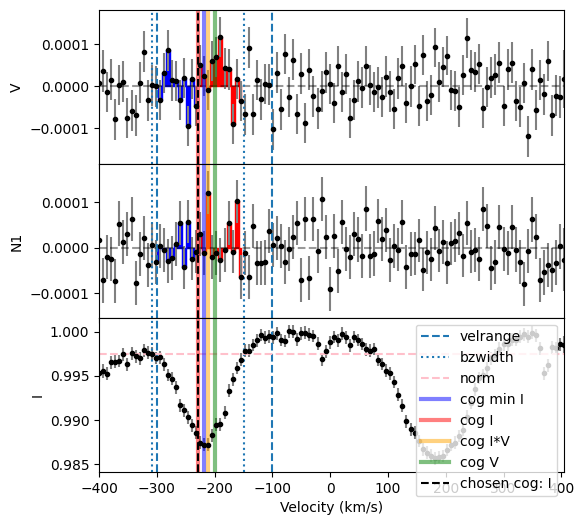

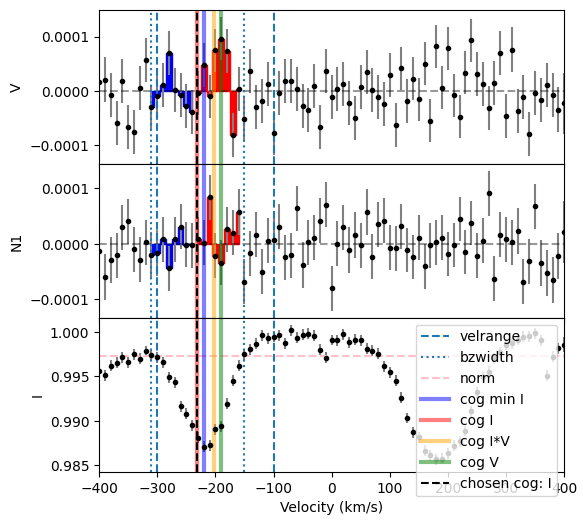

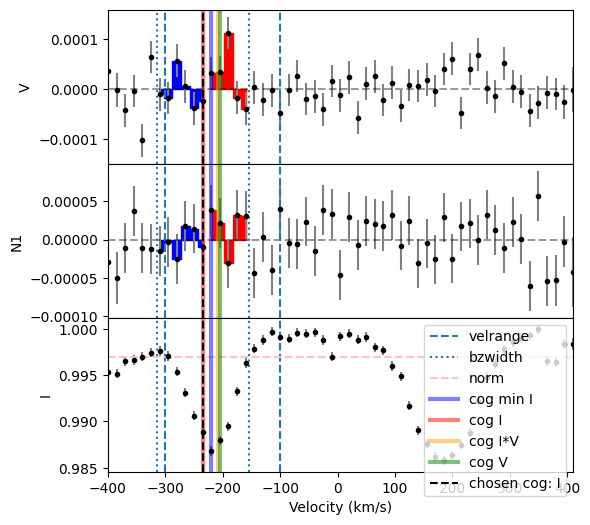

In [15]:
velPixels = [None, 1, 4, 7, 10, 15]
lsd_folder = Path('lsdoutputsHD191201/lsdprofiles_changingVelPixel')
output_folder = Path('lsdoutputsHD191201/bz_normauto')
Bz_results_left = {}

for velPixel in velPixels:
    label = 'default' if velPixel is None else f'vp{velPixel}'
    LSD_outfile = lsd_folder / f'hd191201_E_1308737pn_{label}.lsd'
    lsd = pol.read_lsd(str(LSD_outfile))

    # left component velocity range: [-300,-100], bzwidth=80
    # right component velocity range: [90,280], bzwidth=100
    Bz, fig = lsd.calc_bz(cog='I', norm='auto', velrange=[-300,-100], bzwidth=80,
                          lambda0=500.0, geff=1.2, plot=True, figsize=(6,6))

    result = (f"Bz = {Bz['V bz (G)']:.1f} ± {Bz['V bz sig (G)']:.1f} G\n"
              f"V FAP = {Bz['V FAP']:.3g}\n"
              f"Null Bz = {Bz['N1 bz (G)']:.1f} ± {Bz['N1 bz sig (G)']:.1f} G\n"
              f"Null FAP = {Bz['N1 FAP']:.3g}")

    Bz_results_left[label] = Bz
    # fig.subplots_adjust(bottom=0.23)
    # fig.text(0.15, 0.02, result, fontsize=9, va='bottom')
    # fig.savefig(output_folder / f'hd191201_E_1308737pn_LeftComponent_{label}_normauto_Bz.pdf', bbox_inches='tight')
    print(f'{label}: Bz = {Bz}')

In [18]:
df = pd.DataFrame.from_dict(Bz_results_right, orient='index')
print('bz results for right component with different vp')
display(df.round(3))

bz results for right component with different vp


,V bz (G),V bz sig (G),V FAP,N1 bz (G),N1 bz sig (G),N1 FAP,N2 bz (G),N2 bz sig (G),N2 FAP,norm_method,norm,cog_method,cog,int. range start,int. range end
default,-74.427,86.540,0.116,-23.352,86.747,0.396,0.0,0.0,0.0,auto,0.998,I,183.836,83.836,283.836
vp1,-65.396,91.131,0.189,-3.368,91.345,0.176,0.0,0.0,0.0,auto,0.998,I,183.613,83.613,283.613
vp4,-80.788,85.573,0.348,-31.459,85.780,0.988,0.0,0.0,0.0,auto,0.998,I,184.034,84.034,284.034
vp7,-70.532,76.711,0.586,-51.282,76.895,0.987,0.0,0.0,0.0,auto,0.998,I,183.767,83.767,283.767
vp10,-63.349,76.992,0.197,-50.145,77.182,0.821,0.0,0.0,0.0,auto,0.998,I,183.854,83.854,283.854
vp15,-73.504,71.069,0.338,-47.623,71.229,0.910,0.0,0.0,0.0,auto,0.998,I,184.774,84.774,284.774
